# S6E10 — 特徴量エンジニアリングのための分析

既存の `aaaaaaaaaanya.ipynb` を補完する分析。全件で分布を調べ、同じ分割で特徴量群を比較します。
元の列を残したうえで候補を追加します。満足率の図は関連を示し、因果効果を示しません。

「評価0＝未利用/該当なし」は未確認の仮説です。件数の少ないセルは保留し、
全件EDAから考えた特徴量のCVは探索用として扱います。最終採用前には別のseedや全件で再検証します。

公式: [データ](https://www.kaggle.com/competitions/playground-series-s6e10/data) /
[評価方法](https://www.kaggle.com/competitions/playground-series-s6e10/overview/evaluation)

In [1]:
from pathlib import Path
import sys, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

# ローカル/Kaggle両方でデータを探す。Kaggleでは本ファイルを追加して使うか、
# 次のセルの特徴量関数（埋め込み）だけで実行可能。
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data/raw/train.csv').exists()), Path.cwd())
DATA = next((p for p in [ROOT/'data/raw',
    Path('/kaggle/input/competitions/playground-series-s6e10'),
    Path('/kaggle/input/playground-series-s6e10')] if (p/'train.csv').exists()), None)
if DATA is None: raise FileNotFoundError('train.csv/test.csv を配置してください')
OUT = ROOT/'reports'; OUT.mkdir(exist_ok=True)
(OUT/'figures').mkdir(exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
train = pd.read_csv(DATA/'train.csv'); test = pd.read_csv(DATA/'test.csv')
raw_target = train['satisfaction']
if set(raw_target.dropna().unique()) <= {True, False, 0, 1}:
    train['satisfaction'] = raw_target.astype('int8')
elif set(raw_target.dropna().unique()) <= {'satisfied', 'neutral or dissatisfied'}:
    train['satisfaction'] = raw_target.eq('satisfied').astype('int8')
else: raise ValueError(f'Unexpected target labels: {raw_target.unique()}')
assert train['satisfaction'].nunique() == 2 and not train['satisfaction'].isna().any()
print('Train:', train.shape, 'Test:', test.shape)
print('Satisfaction rate:', train.satisfaction.mean())

Matplotlib is building the font cache; this may take a moment.


Train: (699635, 23) Test: (299844, 22)
Satisfaction rate: 0.44357272006117476


In [2]:
"""Row-local feature candidates: no labels, IDs, or fitted target statistics."""
import numpy as np
import pandas as pd

RATINGS = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness',
]
CATEGORIES = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
PAIRS = [
    ('Inflight wifi service', 'Ease of Online booking'),
    ('Ease of Online booking', 'Online boarding'),
    ('Seat comfort', 'Inflight entertainment'),
    ('Food and drink', 'Cleanliness'),
    ('Seat comfort', 'Cleanliness'),
    ('On-board service', 'Baggage handling'),
]

def feature_groups(df):
    """Return independent candidate families to test against the raw baseline."""
    r = df[RATINGS]
    positive = r.where(r > 0)  # Zero semantics are a hypothesis, not assumed truth.
    zero = pd.DataFrame(index=df.index)
    for i, c in enumerate(RATINGS):
        zero[f'zero_{i}'] = (df[c] == 0).astype('int8')
    zero['zero_count'] = (r == 0).sum(axis=1)
    aggregates = pd.DataFrame({
        'rating_mean': r.mean(axis=1), 'rating_std': r.std(axis=1),
        'rating_min': r.min(axis=1), 'rating_max': r.max(axis=1),
        'rating_range': r.max(axis=1) - r.min(axis=1),
        'rating_low_count': ((r >= 1) & (r <= 2)).sum(axis=1),
        'rating_high_count': (r >= 4).sum(axis=1),
        'rating_positive_mean': positive.mean(axis=1),
    }, index=df.index)
    for name, cols in {
        'digital': ['Inflight wifi service', 'Ease of Online booking', 'Online boarding'],
        'comfort': ['Seat comfort', 'Inflight entertainment', 'Food and drink', 'Cleanliness'],
        'staff': ['On-board service', 'Baggage handling', 'Checkin service'],
    }.items():
        aggregates[f'{name}_mean'] = df[cols].mean(axis=1)
        aggregates[f'{name}_range'] = df[cols].max(axis=1) - df[cols].min(axis=1)
    disagreement = pd.DataFrame(index=df.index)
    for i, (a, b) in enumerate(PAIRS):
        disagreement[f'pair_{i}_equal'] = (df[a] == df[b]).astype('int8')
        disagreement[f'pair_{i}_diff'] = df[a] - df[b]
        # Numeric difference + categorical combination capture different views.
        disagreement[f'pair_{i}_category'] = df[a].astype(str) + ':' + df[b].astype(str)
    context = pd.DataFrame(index=df.index)
    context['customer_travel_class'] = df['Customer Type'] + '|' + df['Type of Travel'] + '|' + df['Class']
    for c in ['Inflight wifi service', 'Online boarding', 'Inflight entertainment']:
        context[f'{c}_by_travel'] = df[c].astype(str) + '|' + df['Type of Travel']
        context[f'{c}_by_class'] = df[c].astype(str) + '|' + df['Class']
    dep, arr = df['Departure Delay in Minutes'], df['Arrival Delay in Minutes']
    delay = pd.DataFrame({
        'arrival_missing': arr.isna().astype('int8'),
        'arrival_minus_departure': arr - dep,
        'delay_recovered': (dep - arr).clip(lower=0),
        'delay_added': (arr - dep).clip(lower=0),
        'departure_zero': (dep == 0).astype('int8'),
        'arrival_zero': (arr == 0).astype('int8'),
        'departure_log': np.log1p(dep), 'arrival_log': np.log1p(arr),
    }, index=df.index)
    return {'zero': zero, 'aggregates': aggregates, 'disagreement': disagreement,
            'context': context, 'delay': delay}

def model_frame(df, families=()):
    raw = df.drop(columns=['id', 'satisfaction'], errors='ignore').copy()
    groups = feature_groups(df) if families else {}
    result = pd.concat([raw] + [groups[f] for f in families], axis=1)
    cats = result.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
    result[cats] = result[cats].fillna('__MISSING__').astype(str)
    nums = result.columns.difference(cats)
    result[nums] = result[nums].astype('float32').fillna(-999)
    return result, cats

In [3]:
def save_table(df, name):
    df.to_csv(OUT/f'{name}.csv', index=False)
    return df

def rate_table(df, keys):
    t = df.groupby(keys, dropna=False, observed=True)['satisfaction'].agg(n='size', rate='mean').reset_index()
    # Wilson 95% intervals, including values exactly 0 or 1.
    z = 1.96; n = t['n']; p = t['rate']; denom = 1 + z*z/n
    center = (p + z*z/(2*n))/denom
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/denom
    t['low'], t['high'] = center-half, center+half
    return t

def finish(fig, name):
    fig.tight_layout(); fig.savefig(OUT/'figures'/f'{name}.png', bbox_inches='tight')
    plt.show(); plt.close(fig)

## 1. 品質・分布差・IDの診断
重複はIDを除いて確認。テストとの重複はラベルを参照せず特徴量だけを比較します。
分布差は全列共通の Jensen–Shannon divergence（0〜1、大きいほど差）で比較。
連続値の区切りは訓練データの分位点を使います。KSのp値は標本が大きいため採否の基準にはしません。

,feature,dtype,train_missing,test_missing,train_unique
0,Age,int64,0,0,75
1,Flight Distance,int64,0,0,3474
2,Inflight wifi service,int64,0,0,6
3,Departure/Arrival time convenient,int64,0,0,6
4,Ease of Online booking,int64,0,0,6
5,Gate location,int64,0,0,6
6,Food and drink,int64,0,0,6
7,Online boarding,int64,0,0,6
8,Seat comfort,int64,0,0,6
9,Inflight entertainment,int64,0,0,6


Duplicate training feature rows: 0
Training rows in conflicting-label duplicate groups: 0


Test rows matching training features (hash check): 0


,feature,js_divergence,ks
1,Flight Distance,1.033307e-05,0.000945
14,Cleanliness,1.005829e-05,NaN
6,Food and drink,8.425535e-06,NaN
10,On-board service,6.532786e-06,NaN
0,Age,5.794868e-06,0.001161
3,Departure/Arrival time convenient,5.568683e-06,NaN
8,Seat comfort,4.908978e-06,NaN
11,Leg room service,4.792599e-06,NaN
12,Baggage handling,4.102783e-06,NaN
7,Online boarding,4.092264e-06,NaN


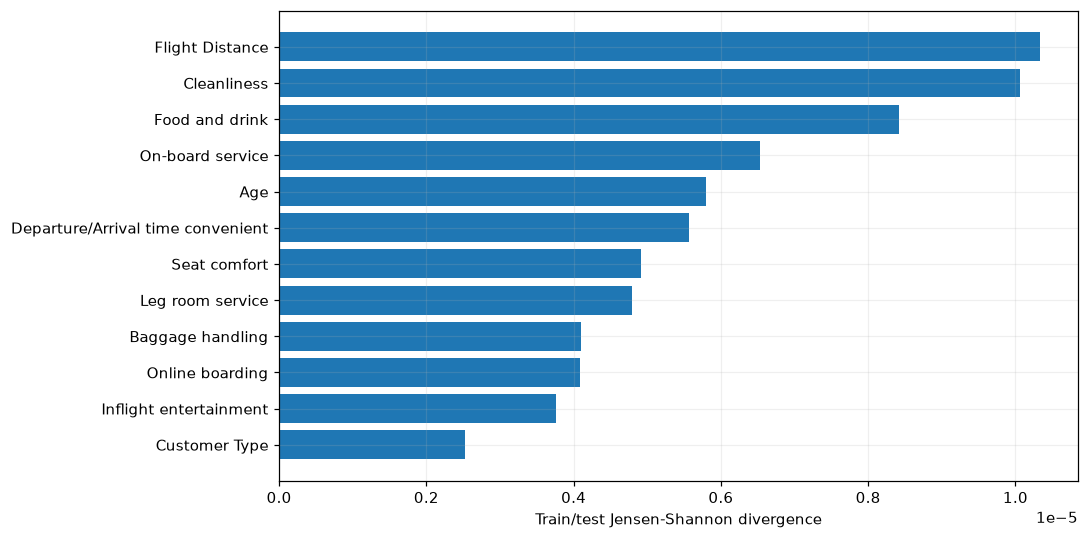

,id_decile,n,rate,low,high
0,"(-0.001, 69963.4]",69964,0.441784,0.438108,0.445467
1,"(69963.4, 139926.8]",69963,0.443706,0.440028,0.447390
2,"(139926.8, 209890.2]",69964,0.442728,0.439050,0.446411
3,"(209890.2, 279853.6]",69963,0.443849,0.440170,0.447533
4,"(279853.6, 349817.0]",69964,0.446072,0.442392,0.449759
5,"(349817.0, 419780.4]",69963,0.445693,0.442013,0.449379
6,"(419780.4, 489743.8]",69963,0.443634,0.439956,0.447319
7,"(489743.8, 559707.2]",69964,0.442913,0.439236,0.446597
8,"(559707.2, 629670.6]",69963,0.442320,0.438642,0.446003
9,"(629670.6, 699634.0]",69964,0.443028,0.439350,0.446712


In [4]:
from scipy.spatial.distance import jensenshannon
features = train.columns.drop(['id','satisfaction']).tolist()
quality = pd.DataFrame({'feature': features,
    'dtype': [str(train[c].dtype) for c in features],
    'train_missing': [train[c].isna().sum() for c in features],
    'test_missing': [test[c].isna().sum() for c in features],
    'train_unique': [train[c].nunique() for c in features]})
display(save_table(quality, 'quality'))
htrain = pd.util.hash_pandas_object(train[features], index=False)
htest = pd.util.hash_pandas_object(test[features], index=False)
print('Duplicate training feature rows:', htrain.duplicated().sum())
print('Training rows in conflicting-label duplicate groups:',
    train.groupby(htrain)['satisfaction'].transform('nunique').gt(1).sum())
print('Test rows matching training features (hash check):', htest.isin(set(htrain)).sum())
shift_rows = []
for c in features:
    a, b = train[c], test[c]
    ks = np.nan
    if pd.api.types.is_numeric_dtype(a) and a.nunique() > 20:
        edges = np.unique(a.quantile(np.linspace(0,1,21)))
        edges[0], edges[-1] = -np.inf, np.inf
        aa = pd.cut(a, edges).astype(str).where(a.notna(), '__NA__')
        bb = pd.cut(b, edges).astype(str).where(b.notna(), '__NA__')
        ks = ks_2samp(a.dropna(), b.dropna()).statistic
    else:
        aa, bb = a.fillna('__NA__').astype(str), b.fillna('__NA__').astype(str)
    levels = sorted(set(aa.unique()) | set(bb.unique()))
    pa = aa.value_counts(normalize=True).reindex(levels, fill_value=0)
    pb = bb.value_counts(normalize=True).reindex(levels, fill_value=0)
    shift_rows.append({'feature':c, 'js_divergence':jensenshannon(pa,pb,base=2)**2, 'ks':ks})
shift = pd.DataFrame(shift_rows).sort_values('js_divergence', ascending=False)
display(save_table(shift, 'distribution_shift'))
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(shift.feature.iloc[:12][::-1], shift.js_divergence.iloc[:12][::-1])
ax.set_xlabel('Train/test Jensen-Shannon divergence'); finish(fig, 'distribution_shift')
idview = train[['id','satisfaction']].copy()
idview['id_decile'] = pd.qcut(idview['id'], 10)
display(save_table(rate_table(idview, ['id_decile']), 'id_deciles'))

## 2. サービス評価は単調か？ 特に0の挙動
評価ごとの満足率と95%区間を比較。相関係数だけでは0の特殊な挙動や閾値を取りこぼします。
0を除いた平均や0フラグを候補にしますが、低評価と未利用のどちらかはデータだけでは確定できません。

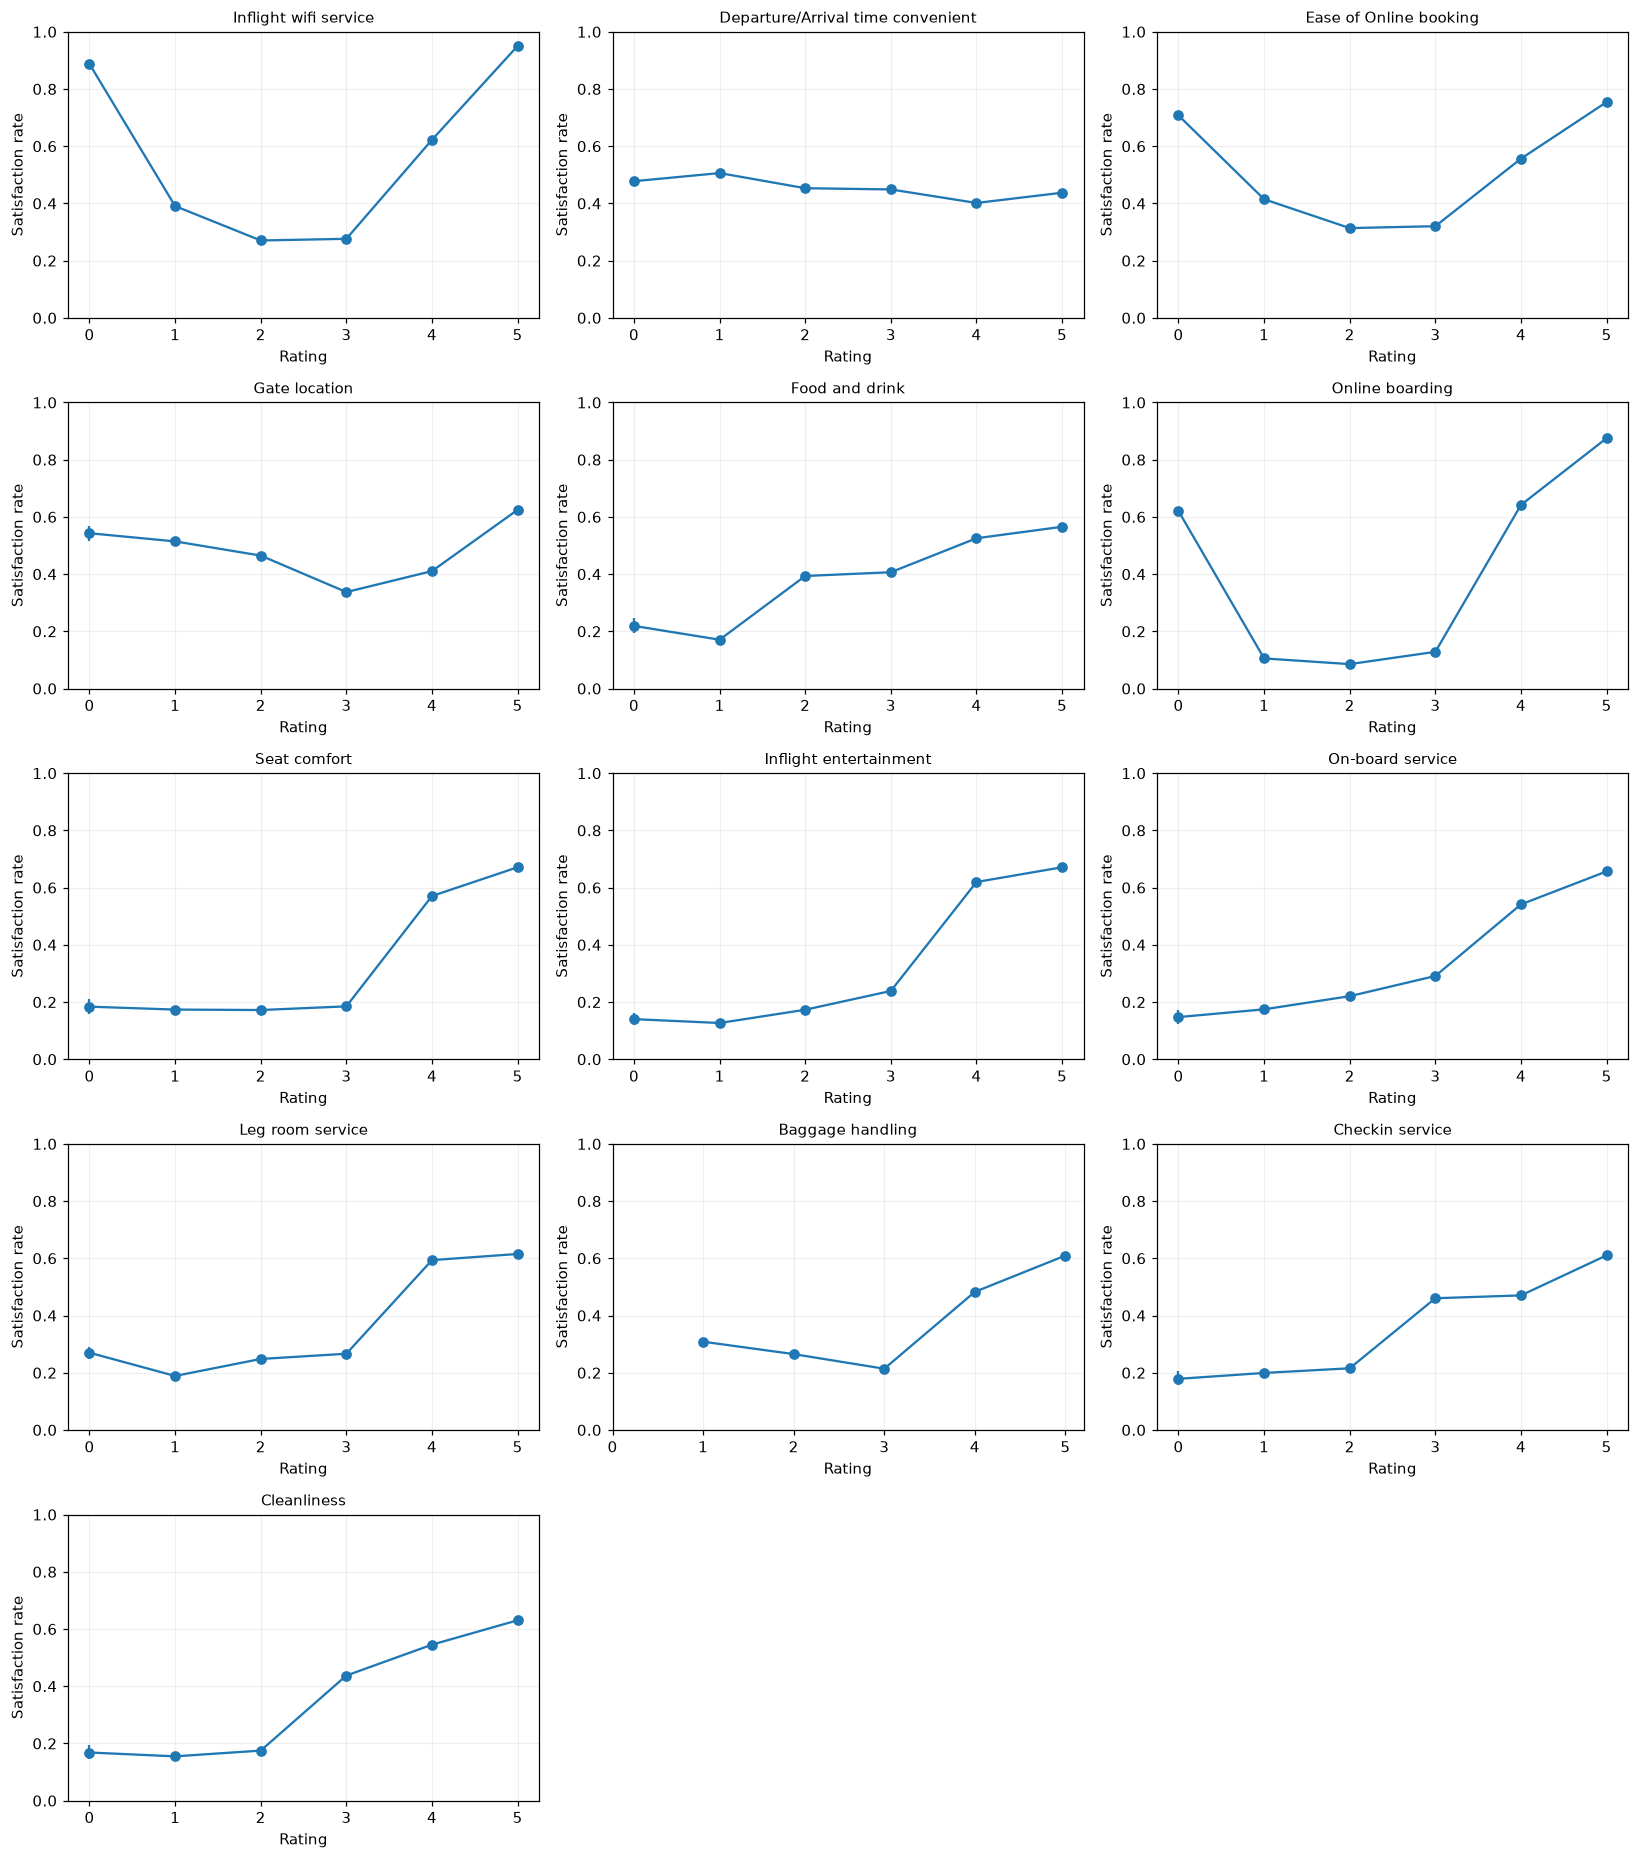

,feature,n,rate,low,high
0,Inflight wifi service,13102,0.887345,0.881818,0.892646
6,Departure/Arrival time convenient,25751,0.477651,0.471554,0.483755
12,Ease of Online booking,16073,0.707584,0.700503,0.714566
18,Gate location,1455,0.542955,0.517279,0.568406
24,Food and drink,1014,0.218935,0.194569,0.245423
30,Online boarding,9147,0.620422,0.610428,0.630315
36,Seat comfort,838,0.183771,0.159011,0.211417
42,Inflight entertainment,1020,0.140196,0.120236,0.162856
48,On-board service,801,0.147316,0.124455,0.173543
54,Leg room service,1693,0.269935,0.249327,0.291585


,zero_count,n,rate,low,high
0,0,654914,0.442418,0.441216,0.443622
1,1,29524,0.323229,0.317917,0.328586
2,2,5343,0.435149,0.421906,0.448485
3,3,6914,0.862453,0.854133,0.870371
4,4,2886,0.939362,0.930057,0.947500
5,5,52,0.942308,0.843572,0.980186
6,6,2,1.000000,0.342372,1.000000


In [5]:
rating_tables = []
fig, axes = plt.subplots(5,3,figsize=(15,17))
for c, ax in zip(RATINGS, axes.ravel()):
    t = rate_table(train, [c]); t['feature'] = c
    t = t.rename(columns={c:'value'}); rating_tables.append(t)
    ax.errorbar(t.value, t.rate, yerr=[t.rate-t.low,t.high-t.rate], fmt='o-')
    ax.set_title(c,fontsize=10); ax.set_ylim(0,1); ax.set_xticks(range(6))
    ax.set_xlabel('Rating'); ax.set_ylabel('Satisfaction rate')
for ax in axes.ravel()[len(RATINGS):]: ax.axis('off')
finish(fig, 'rating_response')
ratings_long = pd.concat(rating_tables, ignore_index=True)
save_table(ratings_long, 'rating_response')
display(ratings_long.query('value == 0')[['feature','n','rate','low','high']])
zero_view = train.assign(zero_count=train[RATINGS].eq(0).sum(axis=1))
display(save_table(rate_table(zero_view, ['zero_count']), 'zero_count_response'))

## 3. 顧客層と評価の相互作用
同じ評価値でも旅行目的、クラス、顧客タイプで満足率が違うか確認。
少数セルは伏せ、件数表も保存します。差は他の特徴量による交絡を含むため、CVで追加効果を確認します。

,value,n,rate,low,high,feature
0,Female,347952,0.437994,0.436346,0.439644,Gender
1,Male,351683,0.449092,0.447449,0.450736,Gender
2,Loyal Customer,576990,0.495145,0.493855,0.496436,Customer Type
3,disloyal Customer,122645,0.200946,0.198713,0.203198,Customer Type
4,Business travel,497441,0.584337,0.582966,0.585706,Type of Travel
5,Personal Travel,202194,0.097263,0.095979,0.098562,Type of Travel
6,Business,342212,0.725311,0.723813,0.726804,Class
7,Eco,327404,0.167558,0.166282,0.168841,Class
8,Eco Plus,30019,0.242180,0.237367,0.247059,Class


,Customer Type,Type of Travel,Class,n,rate,low,high
0,Loyal Customer,Business travel,Business,294376,0.791753,0.790282,0.793216
1,Loyal Customer,Business travel,Eco,65542,0.412728,0.408964,0.416502
2,Loyal Customer,Business travel,Eco Plus,14983,0.394847,0.387048,0.402701
3,Loyal Customer,Personal Travel,Business,3939,0.111957,0.102486,0.122185
4,Loyal Customer,Personal Travel,Eco,185691,0.097070,0.095732,0.098425
5,Loyal Customer,Personal Travel,Eco Plus,12459,0.095353,0.090319,0.100635
6,disloyal Customer,Business travel,Business,43896,0.334791,0.330391,0.339220
7,disloyal Customer,Business travel,Eco,76070,0.128461,0.126102,0.130857
8,disloyal Customer,Business travel,Eco Plus,2574,0.064103,0.055274,0.074230
9,disloyal Customer,Personal Travel,Business,1,0.000000,0.000000,0.793457


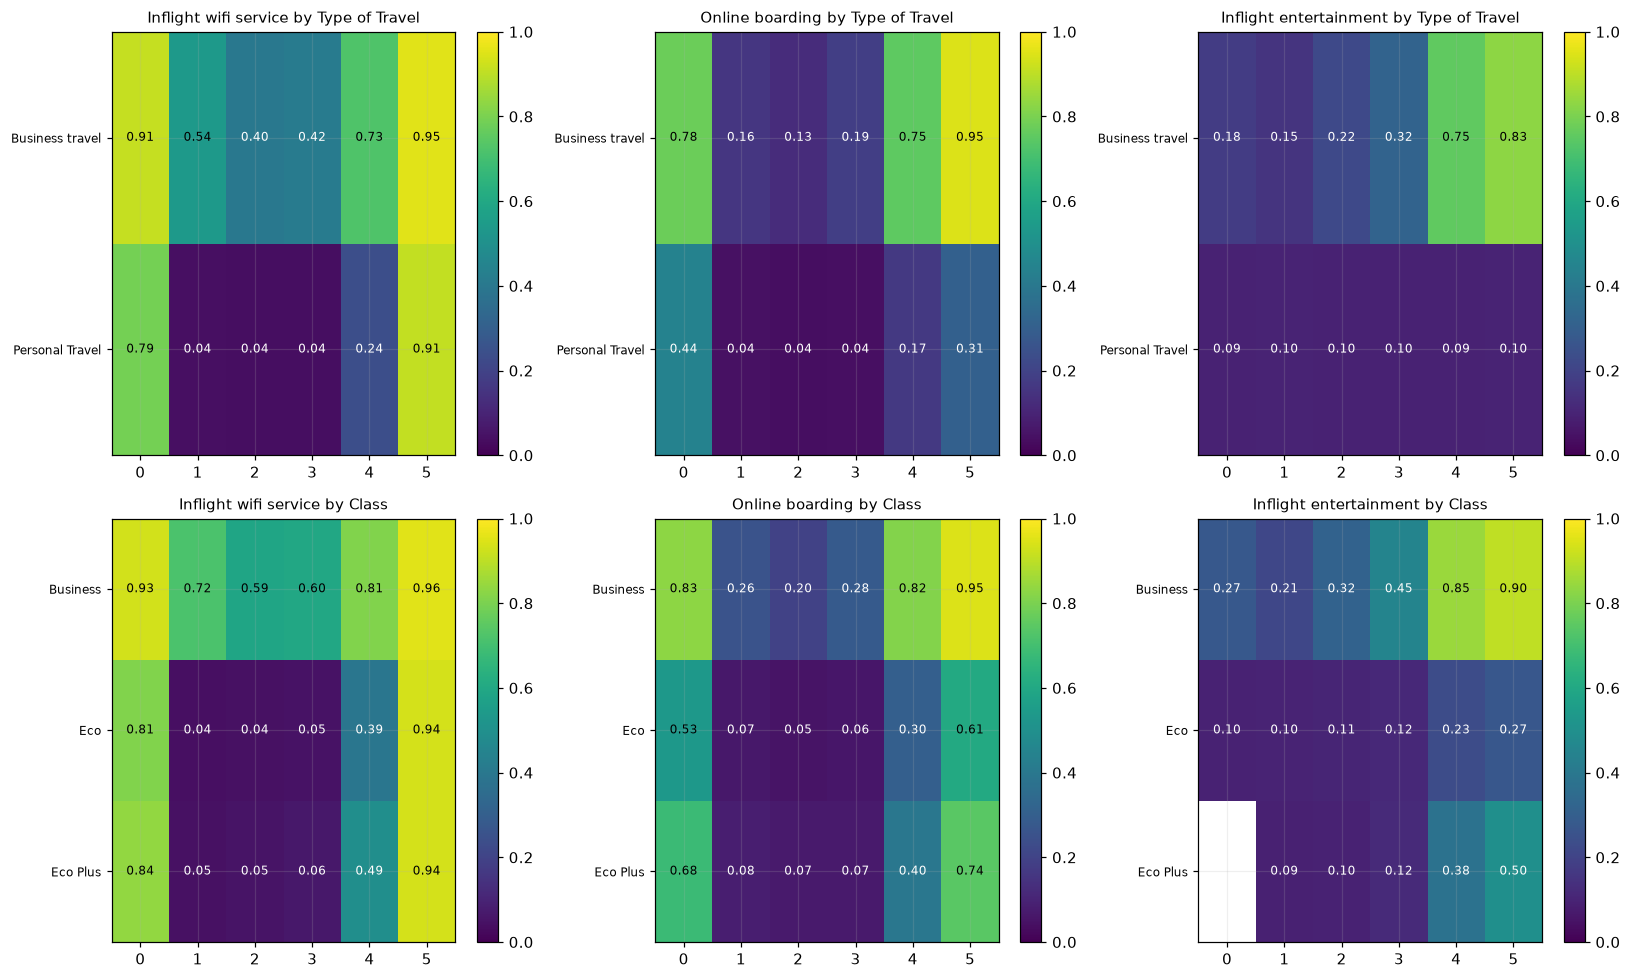

,segment,rating,n,rate,low,high,segment_feature,rating_feature
0,Business travel,0,10418,0.911883,0.906287,0.917176,Type of Travel,Inflight wifi service
1,Business travel,1,75651,0.539755,0.536201,0.543305,Type of Travel,Inflight wifi service
2,Business travel,2,120012,0.401193,0.398423,0.403969,Type of Travel,Inflight wifi service
3,Business travel,3,116553,0.416626,0.413798,0.419459,Type of Travel,Inflight wifi service
4,Business travel,4,100901,0.725037,0.722274,0.727784,Type of Travel,Inflight wifi service
...,...,...,...,...,...,...,...,...
85,Eco Plus,1,4162,0.092984,0.084533,0.102186,Class,Inflight entertainment
86,Eco Plus,2,6550,0.095573,0.088688,0.102932,Class,Inflight entertainment
87,Eco Plus,3,6601,0.117861,0.110304,0.125863,Class,Inflight entertainment
88,Eco Plus,4,6833,0.376994,0.365575,0.388551,Class,Inflight entertainment


In [6]:
segment_tables = []
for c in CATEGORIES:
    t = rate_table(train,[c]); t['feature'] = c
    t = t.rename(columns={c:'value'}); segment_tables.append(t)
display(save_table(pd.concat(segment_tables,ignore_index=True), 'category_response'))
display(save_table(rate_table(train,['Customer Type','Type of Travel','Class']), 'customer_segments'))
interaction_tables = []
fig, axes = plt.subplots(2,3,figsize=(15,9))
for row, segment in enumerate(['Type of Travel','Class']):
    for col, rating in enumerate(['Inflight wifi service','Online boarding','Inflight entertainment']):
        t = rate_table(train,[segment,rating]); t['segment_feature']=segment; t['rating_feature']=rating
        interaction_tables.append(t.rename(columns={segment:'segment',rating:'rating'}))
        pivot = t.assign(rate=t.rate.where(t.n >= 200)).pivot(index=segment,columns=rating,values='rate')
        ax=axes[row,col]; im=ax.imshow(pivot, vmin=0,vmax=1,cmap='viridis',aspect='auto')
        ax.set_xticks(range(len(pivot.columns)),pivot.columns)
        ax.set_yticks(range(len(pivot.index)),pivot.index,fontsize=8)
        ax.set_title(f'{rating} by {segment}',fontsize=10)
        for i in range(len(pivot)):
            for j in range(len(pivot.columns)):
                if pd.notna(pivot.iloc[i,j]): ax.text(j,i,f'{pivot.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,color='white' if pivot.iloc[i,j]<.5 else 'black')
        fig.colorbar(im,ax=ax)
finish(fig,'segment_interactions')
save_table(pd.concat(interaction_tables,ignore_index=True), 'segment_interactions')

## 4. 評価の一致・食い違いと遅延
合成データでは似た項目の一致自体に情報がある可能性があります。
一致フラグ、評価差、評価ペアのカテゴリを別の表現として候補化。
遅延は差分・回復量・ゼロ・欠損フラグを調べます。元の遅延列は残します。

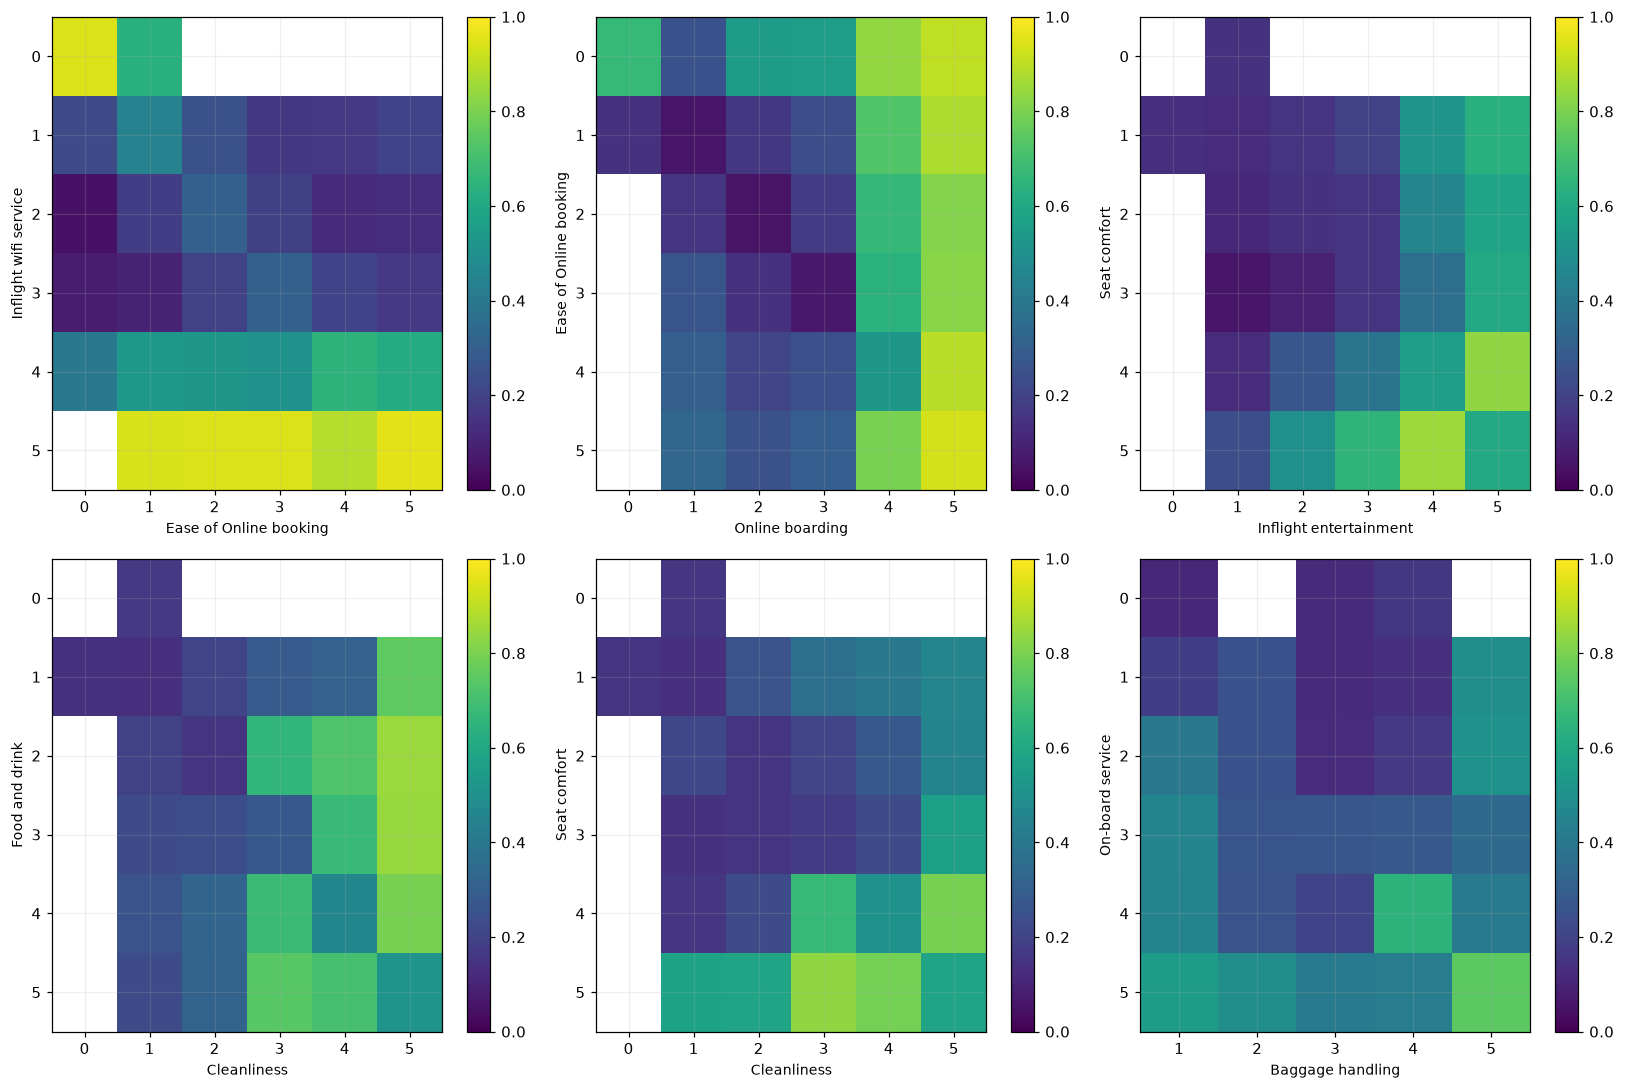

,equal,n,rate,low,high,pair,test_equal_rate
0,False,170143,0.331856,0.329622,0.334097,Inflight wifi service / Ease of Online booking,0.753649
1,True,529492,0.479471,0.478125,0.480817,Inflight wifi service / Ease of Online booking,0.753649
2,False,346451,0.613331,0.611708,0.614951,Ease of Online booking / Online boarding,0.503288
3,True,353184,0.277051,0.275577,0.278529,Ease of Online booking / Online boarding,0.503288
4,False,235569,0.550611,0.548602,0.552619,Seat comfort / Inflight entertainment,0.663819
5,True,464066,0.389238,0.387836,0.390641,Seat comfort / Inflight entertainment,0.663819
6,False,241393,0.643503,0.641590,0.645411,Food and drink / Cleanliness,0.653633
7,True,458242,0.338254,0.336885,0.339625,Food and drink / Cleanliness,0.653633
8,False,242819,0.587425,0.585466,0.589382,Seat comfort / Cleanliness,0.653870
9,True,456816,0.367108,0.365712,0.368507,Seat comfort / Cleanliness,0.653870


,delay_delta_bin,n,rate,low,high
0,"(-inf, -15.0]",3697,0.411685,0.395921,0.427633
1,"(-15.0, -1.0]",49966,0.417224,0.412907,0.421554
2,"(-1.0, 0.0]",607705,0.451362,0.450111,0.452614
3,"(0.0, 1.0]",4575,0.446776,0.432420,0.461221
4,"(1.0, 15.0]",28527,0.355067,0.349534,0.360639
5,"(15.0, inf]",4873,0.286477,0.273954,0.299335
6,NaN,292,0.363014,0.309967,0.419618


,arrival_missing,n,rate,low,high
0,False,699343,0.443606,0.442442,0.444771
1,True,292,0.363014,0.309967,0.419618


Age


,bin,n,rate,low,high
0,"(6.999, 22.0]",85218,0.205626,0.202925,0.208352
1,"(22.0, 25.0]",56156,0.315656,0.311825,0.319513
2,"(25.0, 30.0]",79908,0.338952,0.335678,0.342242
3,"(30.0, 36.0]",73788,0.357375,0.353925,0.360840
4,"(36.0, 40.0]",72141,0.483373,0.479727,0.487020
5,"(40.0, 43.0]",53972,0.622526,0.618428,0.626607
6,"(43.0, 47.0]",68966,0.608039,0.604389,0.611676
7,"(47.0, 52.0]",78186,0.593623,0.590176,0.597061
8,"(52.0, 57.0]",65553,0.608347,0.604605,0.612078
9,"(57.0, 85.0]",65747,0.379318,0.375616,0.383034


Flight Distance


,bin,n,rate,low,high
0,"(66.999, 508.0]",70053,0.317802,0.314364,0.321260
1,"(508.0, 591.0]",71037,0.302223,0.298857,0.305610
2,"(591.0, 680.0]",68903,0.290263,0.286886,0.293664
3,"(680.0, 842.0]",69910,0.299213,0.295830,0.302619
4,"(842.0, 954.0]",70398,0.289596,0.286257,0.292958
5,"(954.0, 1189.0]",69653,0.277260,0.273948,0.280597
6,"(1189.0, 1620.0]",70230,0.491827,0.488130,0.495525
7,"(1620.0, 2240.0]",69587,0.668358,0.664850,0.671846
8,"(2240.0, 2933.0]",69910,0.702374,0.698974,0.705753
9,"(2933.0, 4983.0]",69954,0.798196,0.795205,0.801154


Departure Delay in Minutes


,bin,n,rate,low,high
0,"(-0.001, 489.0]",699635,0.443573,0.442409,0.444737


In [7]:
pairs = []
fig, axes = plt.subplots(2,3,figsize=(15,10))
for i, ((a,b),ax) in enumerate(zip(PAIRS,axes.ravel())):
    t=rate_table(train,[a,b]); t['pair']=f'{a} / {b}'
    pairs.append(t.rename(columns={a:'left',b:'right'}))
    pivot=t.assign(rate=t.rate.where(t.n>=200)).pivot(index=a,columns=b,values='rate')
    im=ax.imshow(pivot,vmin=0,vmax=1,cmap='viridis',aspect='auto')
    ax.set_xticks(range(len(pivot.columns)),pivot.columns); ax.set_yticks(range(len(pivot.index)),pivot.index)
    ax.set_xlabel(b,fontsize=9); ax.set_ylabel(a,fontsize=9); fig.colorbar(im,ax=ax)
finish(fig,'rating_pairs')
save_table(pd.concat(pairs,ignore_index=True),'rating_pairs')
equality_rows=[]
for a,b in PAIRS:
    view=train.assign(equal=train[a].eq(train[b]))
    t=rate_table(view,['equal']); t['pair']=f'{a} / {b}'
    t['test_equal_rate']=test[a].eq(test[b]).mean()
    equality_rows.append(t)
display(save_table(pd.concat(equality_rows,ignore_index=True),'pair_equality'))
delays=train[['satisfaction','Departure Delay in Minutes','Arrival Delay in Minutes']].copy()
delays['delay_delta']=delays['Arrival Delay in Minutes']-delays['Departure Delay in Minutes']
delays['delay_delta_bin']=pd.cut(delays.delay_delta,[-np.inf,-15,-1,0,1,15,np.inf])
display(save_table(rate_table(delays,['delay_delta_bin']),'delay_delta_response'))
delays['arrival_missing']=delays['Arrival Delay in Minutes'].isna()
display(save_table(rate_table(delays,['arrival_missing']),'missing_response'))
for c in ['Age','Flight Distance','Departure Delay in Minutes']:
    v=train.assign(bin=pd.qcut(train[c],10,duplicates='drop'))
    print(c); display(rate_table(v,['bin']))

## 5. 特徴量群ごとの交差検証（一次スクリーニング）

速度のため訓練から層化抽出した120,000行で3-fold。全候補で同じ行・分割・seed・モデルを使用。
CatBoost 400木・深さ6を固定し、検証スコアで反復数を選ばない設定です。
ID・目的変数を特徴量から除外し、候補はすべて行単位で作成。ターゲットエンコーディングは使用しません。

候補の選定に全件EDAを使っているため、これは探索用比較であり未見データでの最終評価ではありません。
小さな差は未確定です。採用には全件・追加seed・別モデルでの再現が必要。
PCAやt-SNEの見た目の分離だけを理由に特徴量を採用しません。

raw           fold=0 AUC=0.957774 seconds=5.8


raw           fold=1 AUC=0.957949 seconds=6.4


raw           fold=2 AUC=0.956570 seconds=5.8


zero          fold=0 AUC=0.957616 seconds=5.9


zero          fold=1 AUC=0.958082 seconds=5.9


...

all           fold=0 AUC=0.958364 seconds=15.3


all           fold=1 AUC=0.957579 seconds=15.1


all           fold=2 AUC=0.956542 seconds=15.2


,experiment,auc_mean,auc_std,features,oof_auc,delta_oof,delta_fold_min,delta_fold_max
0,delay,0.957566,0.000984,29,0.957541,0.000129,-0.000137,0.000438
1,context,0.957562,0.000764,28,0.957541,0.000128,-0.000298,0.000504
2,all,0.957495,0.000914,82,0.957462,0.000050,-0.000370,0.000591
3,raw,0.957431,0.000751,21,0.957412,0.000000,0.000000,0.000000
4,zero,0.957365,0.000870,35,0.957352,-0.000061,-0.000172,0.000133
5,disagreement,0.957360,0.000760,39,0.957340,-0.000072,-0.000113,-0.000014
6,aggregates,0.957242,0.001095,35,0.957223,-0.000189,-0.000551,0.000477


,experiment,feature,importance
19,all,Inflight wifi service_by_travel,14.009469
33,all,customer_travel_class,11.236681
24,all,Online boarding_by_travel,6.308427
18,all,Inflight wifi service_by_class,5.964651
6,all,Customer Type,4.435309
26,all,Type of Travel,4.402314
66,all,staff_mean,4.033292
22,all,Online boarding,3.929908
42,all,pair_0_equal,3.443203
15,all,Inflight entertainment_by_class,2.817693


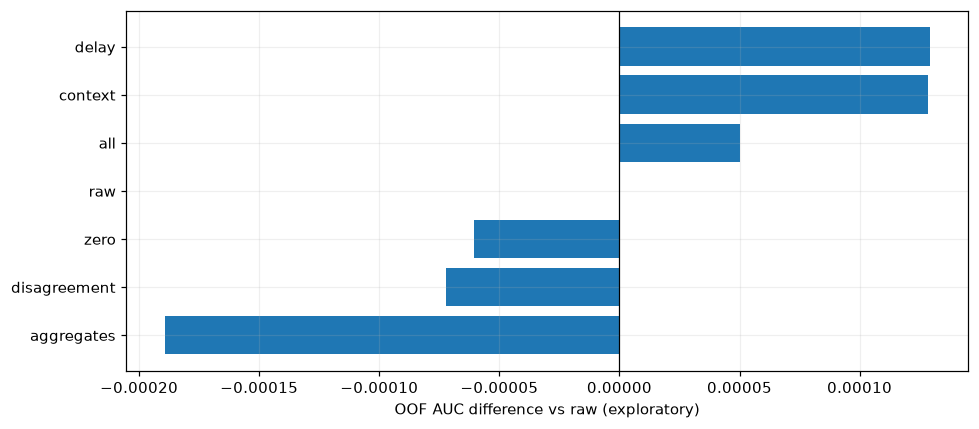

In [8]:
CV_N = min(120_000,len(train))
if CV_N < len(train):
    sample_idx,_=train_test_split(np.arange(len(train)), train_size=CV_N,
        stratify=train.satisfaction, random_state=SEED)
else: sample_idx=np.arange(len(train))
sample=train.iloc[sample_idx].reset_index(drop=True)
y=sample.satisfaction.to_numpy()
folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(sample,y))
experiments={'raw':[], **{k:[k] for k in feature_groups(sample)},
             'all':list(feature_groups(sample))}
results=[]; oofs={}; importances=[]
for name,families in experiments.items():
    X,cats=model_frame(sample,families)
    oof=np.zeros(len(sample)); scores=[]
    for fold,(itr,iva) in enumerate(folds):
        start=time.time()
        model=CatBoostClassifier(iterations=400,depth=6,learning_rate=.08,
            loss_function='Logloss',random_seed=SEED+fold,thread_count=6,
            verbose=False,allow_writing_files=False)
        model.fit(X.iloc[itr],y[itr],cat_features=cats)
        p=model.predict_proba(X.iloc[iva])[:,1]; oof[iva]=p
        auc=roc_auc_score(y[iva],p); scores.append(auc)
        results.append({'experiment':name,'fold':fold,'auc':auc,'seconds':time.time()-start,'features':X.shape[1]})
        if name in ['raw','all']:
            importances.append(pd.DataFrame({'experiment':name,'fold':fold,
                'feature':X.columns,'importance':model.feature_importances_}))
        print(f'{name:13s} fold={fold} AUC={auc:.6f} seconds={time.time()-start:.1f}',flush=True)
        pd.DataFrame(results).to_csv(OUT/'cv_folds.csv',index=False)
    oofs[name]=oof
    np.savez_compressed(OUT/f'oof_{name}.npz',id=sample.id.to_numpy(),y=y,pred=oof)
fold_results=pd.DataFrame(results)
summary=fold_results.groupby('experiment').agg(auc_mean=('auc','mean'),auc_std=('auc','std'),features=('features','first'))
summary['oof_auc']=[roc_auc_score(y,oofs[name]) for name in summary.index]
summary['delta_oof']=summary.oof_auc-summary.loc['raw','oof_auc']
paired=fold_results.pivot(index='fold',columns='experiment',values='auc')
for name in summary.index:
    delta=paired[name]-paired['raw']
    summary.loc[name,'delta_fold_min']=delta.min(); summary.loc[name,'delta_fold_max']=delta.max()
summary=summary.sort_values('oof_auc',ascending=False)
display(save_table(summary.reset_index(),'cv_summary'))
importance=pd.concat(importances).groupby(['experiment','feature']).importance.mean().reset_index()
save_table(importance,'model_importance')
display(importance.query("experiment == 'all'").sort_values('importance',ascending=False).head(25))
fig,ax=plt.subplots(figsize=(9,4)); order=summary.index.tolist()
ax.barh(order[::-1],summary.loc[order[::-1],'delta_oof']); ax.axvline(0,color='black',lw=.8)
ax.set_xlabel('OOF AUC difference vs raw (exploratory)'); finish(fig,'cv_ablation')

## 6. 読み方と次の実験

- `rating_response.csv`：0や閾値の挙動。ただし満足率が高くても他の列を入れた後の追加効果は未確定。
- `segment_interactions.csv`：旅行目的・クラスで評価の意味が変わるか。件数と区間も確認。
- `rating_pairs.csv` / `pair_equality.csv`：一致や差の候補。強い関連があっても元の列でモデルが表現できる場合がある。
- `cv_summary.csv`：各群を単独追加した比較。複数foldで方向が一致する候補を優先。
- `model_importance.csv`：モデル内の使用量の目安。相関した列の重要度は分散するため、採否は追加比較で決める。

改善した候補は全件で深いモデル・追加seedへ進め、OOF予測を保存してモデル間の組み合わせを検証。
悪化した特徴量はこの設定での不採用候補であり、全モデルで無効と断定しません。

## 今回の実測結果

| 追加する特徴量群 | OOF AUC | 基準との差 | foldごとの最小差 | foldごとの最大差 |
|---|---:|---:|---:|---:|
| 遅延の派生量 | 0.957541 | +0.000129 | -0.000137 | +0.000438 |
| 顧客層との組み合わせ | 0.957541 | +0.000128 | -0.000298 | +0.000504 |
| 全候補 | 0.957462 | +0.000050 | -0.000370 | +0.000591 |
| 元の列のみ | 0.957412 | +0.000000 | +0.000000 | +0.000000 |
| 0フラグ・0件数 | 0.957352 | -0.000061 | -0.000172 | +0.000133 |
| 評価の一致・差・ペア | 0.957340 | -0.000072 | -0.000113 | -0.000014 |
| 評価の集約 | 0.957223 | -0.000189 | -0.000551 | +0.000477 |

全foldで改善した群：該当なし。

これは12万行での探索用比較です。全件・追加seedで再検証してください。